In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
tr = pd.read_csv("../data/dataset_train.csv")
y = tr["AGE_RANGE"]

# Estrutura e tipos

In [4]:
tr.shape;
tr.dtypes.value_counts()

str        229
float64      5
int64        3
Name: count, dtype: int64

In [5]:
tr.select_dtypes(exclude="number").nunique().describe() # nº de categorias por coluna

count    229.000000
mean      11.279476
std       22.665775
min        1.000000
25%        4.000000
50%        5.000000
75%        7.000000
max      165.000000
dtype: float64

# Distribuição das classes (gráfico de barras)

Text(0, 0.5, 'nº pessoas')

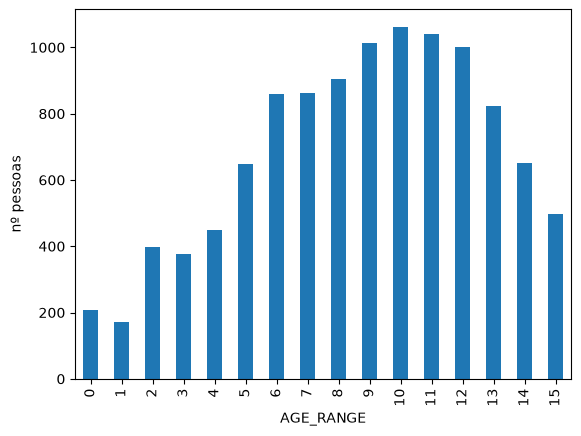

In [7]:
y.value_counts().sort_index().plot.bar();
plt.xlabel("AGE_RANGE");
plt.ylabel("nº pessoas")

# Valores em falta e "falsos" em falta

In [12]:
tr.isna().mean().sort:values(ascending=False).head(10) # só IN16 tem NaN
s = tr.select_dtypes(exclude="number")
(s == "Não aplicável").mean().sort_values(ascending=False).head(15)
(s == "Sem resposta").mean().sort_values(ascending=False).head(15)

IN57       0.049444
IN67       0.040960
SS3        0.038314
IN7h       0.035486
IN54       0.032385
IN14       0.028462
IN50       0.027550
BM2        0.027185
IN55       0.027094
IN7f       0.025360
IN53       0.022806
IN56       0.021620
IN51       0.020525
IN7e       0.020161
PA8_NAC    0.019796
dtype: float64

# Duplicados, constantes e IDs

In [13]:
tr.duplicated().sum()
[c for c in tr.columns if tr[c].nunique()<=1] # PROXY, COUNTRY
tr["PID"].corr(y)
len(set(tr.PID) & set(pd.read_csv("../data/dataset_test_X.csv").PID)) # 0

0

# Relação das variáveis com a faixa etária

In [14]:
# exemplo: situação laboral vs faixa etária (tabela cruzada em %)
pd.crosstab(tr["MAINSTAT"], y, normalize = "index").round(2)
# exemplo : saúde autoavaliada (HS1) por faixa
pd.crosstab(y, tr["HS1"], normalize="index").round(2)

HS1,Bom,Mau,Muito bom,Muito mau,Razoável,Sem resposta
AGE_RANGE,,,,,,
0,0.51,0.00,0.40,0.00,0.08,0.00
1,0.46,0.00,0.43,0.01,0.10,0.01
2,0.51,0.01,0.32,0.00,0.16,0.00
3,0.53,0.01,0.32,0.01,0.14,0.00
4,0.57,0.02,0.23,0.01,0.17,0.00
5,0.57,0.01,0.19,0.00,0.22,0.00
6,0.53,0.03,0.16,0.01,0.28,0.00
7,0.42,0.05,0.13,0.02,0.38,0.00
8,0.39,0.09,0.08,0.02,0.42,0.00


# Tabelas por grupo etário (para o Elemento 4)

In [15]:
# para cada variável escolhida: proporção de cada resposta em cada faixa
tabela = pd.crosstab(y, tr["HS1"], normalize="index")
tabela.to_csv("../docs/tabela_HS1_por_faixa.csv")